# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/barak-hub/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

### Research Title
Predicting Google Search Engagement Opportunities Using Machine Learning

### Research Question
Can historical Google Search performance signals help identify content opportunities with low click-through rates (CTR), and can machine learning improve opportunity ranking compared with a simple rule-based baseline?

### Problem Statement
Some content receives many impressions in Google Search but relatively few clicks. This may indicate opportunities for improvement, although low CTR can also result from ranking position, search intent, or query relevance.

### Decision Supported
This research aims to help SEO specialists prioritize which content should be investigated for potential improvement.

### Proposed Approach
I will use FlyRank's anonymized search performance data to investigate engagement patterns, develop a machine learning approach, and compare it against the rule-based baseline created in ML-07.

### Expected Value
The project aims to provide evidence-based recommendations that support SEO decision-making. Any improvement over the baseline must be demonstrated through evaluation rather than assumed.

### Data Description

This study uses FlyRank's anonymized `fact_content_query_90d.parquet` dataset from the FlyRank Internship Warehouse on Hugging Face.

The dataset contains 2,414,248 records and 21 columns, covering April 2 to June 30, 2026. Each record represents an anonymized client–content–query combination.

The data includes Google Search impressions, clicks, average ranking position, query-length features, and previous and latest 30-day performance metrics.

### Initial Data Quality Findings

- The dataset represents 52 anonymized clients.
- No missing values were found in the seven search-performance columns checked.
- No records had zero impressions over the 90-day reporting period.
- The dataset contains a single 90-day reporting window.

### Data Privacy

Client identities, website URLs, and private search queries will not be published. Only anonymized identifiers, aggregated statistics, and public-safe findings will be used.

### Limitations

The dataset contains aggregated historical observations rather than individual search events. Ranking position, search intent, and other unobserved factors may influence CTR. The overlapping 30-day and 90-day metrics must be handled carefully to avoid data leakage.

In [1]:
import pandas as pd

from google.colab import userdata
from huggingface_hub import hf_hub_download

token = userdata.get("HF_TOKEN")

file_path = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="fact_content_query_90d.parquet",
    repo_type="dataset",
    token=token
)

df = pd.read_parquet(file_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nDate windows:")
print(df[["window_start", "window_end"]].drop_duplicates().head(10))

fact_content_query_90d.parquet: reconstructing file:   0%|          |  0.00B / 60.7MB            

fact_content_query_90d.parquet: downloading bytes:           |  0.00B            

Dataset shape: (2414248, 21)

Columns:
['client_hash_id', 'content_hash_id', 'query_hash_id', 'query_char_count', 'query_token_count', 'window_start', 'window_end', 'impressions_90d', 'clicks_90d', 'impressions_last30', 'clicks_last30', 'impressions_prev30', 'clicks_prev30', 'avg_position_90d', 'avg_position_last30', 'avg_position_prev30', 'content_total_impressions_90d', 'content_visible_query_count', 'rare_query_count', 'rare_impressions_share', 'anonymized_impressions_share']

Date windows:
  window_start  window_end
0   2026-04-02  2026-06-30


In [2]:
# Check missing values
important_columns = [
    "impressions_90d",
    "clicks_90d",
    "avg_position_90d",
    "impressions_prev30",
    "clicks_prev30",
    "impressions_last30",
    "clicks_last30"
]

print("Missing values:")
print(df[important_columns].isna().sum())

print("\nZero-impression records:")
print((df["impressions_90d"] == 0).sum())

print("\nUnique clients:")
print(df["client_hash_id"].nunique())

Missing values:
impressions_90d       0
clicks_90d            0
avg_position_90d      0
impressions_prev30    0
clicks_prev30         0
impressions_last30    0
clicks_last30         0
dtype: int64

Zero-impression records:
0

Unique clients:
52


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

In [3]:

# Examine historical and latest 30-day performance

columns = [
    "impressions_prev30",
    "clicks_prev30",
    "impressions_last30",
    "clicks_last30",
    "avg_position_prev30",
    "avg_position_last30"
]

print("30-day performance summary:")
print(df[columns].describe().round(2).to_string())

print("\nRecords with impressions in both periods:")
print(
    (
        (df["impressions_prev30"] > 0) &
        (df["impressions_last30"] > 0)
    ).sum()
)


30-day performance summary:
       impressions_prev30  clicks_prev30  impressions_last30  clicks_last30  avg_position_prev30  avg_position_last30
count          2414248.00     2414248.00          2414248.00     2414248.00           2084828.00           1883490.00
mean                31.16           0.07               26.04           0.06                22.48                23.56
std                424.27           0.77              355.66           0.71                24.96                26.80
min                  0.00           0.00                0.00           0.00                 0.00                 0.00
25%                  3.00           0.00                1.00           0.00                 6.00                 5.72
50%                  7.00           0.00                5.00           0.00                10.20                10.00
75%                 18.00           0.00               14.00           0.00                33.67                36.47
max             280503.00   

In [4]:

# Examine the potential prediction target

import numpy as np

eligible = df[
    (df["impressions_prev30"] > 0) &
    (df["impressions_last30"] > 0)
].copy()

eligible["ctr_prev30"] = (
    eligible["clicks_prev30"] /
    eligible["impressions_prev30"]
)

eligible["ctr_last30"] = (
    eligible["clicks_last30"] /
    eligible["impressions_last30"]
)

print("Eligible records:", len(eligible))

print("\nPrevious and latest CTR summary:")
print(
    eligible[["ctr_prev30", "ctr_last30"]]
    .describe()
    .round(4)
)

print("\nRecords with zero clicks in latest period:")
print((eligible["clicks_last30"] == 0).sum())

print("\nRecords with latest CTR above zero:")
print((eligible["ctr_last30"] > 0).sum())


Eligible records: 1704767

Previous and latest CTR summary:
         ctr_prev30    ctr_last30
count  1.704767e+06  1.704767e+06
mean   2.800000e-03  2.600000e-03
std    2.590000e-02  2.680000e-02
min    0.000000e+00  0.000000e+00
25%    0.000000e+00  0.000000e+00
50%    0.000000e+00  0.000000e+00
75%    0.000000e+00  0.000000e+00
max    1.000000e+00  1.000000e+00

Records with zero clicks in latest period:
1626443

Records with latest CTR above zero:
78324


In [5]:

# Examine how impression volume affects the target

eligible["impression_bucket"] = pd.cut(
    eligible["impressions_last30"],
    bins=[0, 10, 100, 1000, float("inf")],
    labels=["1-10", "11-100", "101-1000", "1001+"],
    include_lowest=True
)

volume_check = (
    eligible.groupby("impression_bucket", observed=True)
    .agg(
        n=("clicks_last30", "size"),
        impressions=("impressions_last30", "sum"),
        clicks=("clicks_last30", "sum"),
        records_with_clicks=("clicks_last30", lambda x: (x > 0).sum())
    )
)

volume_check["click_rate"] = (
    volume_check["records_with_clicks"] / volume_check["n"]
)

volume_check["ctr"] = (
    volume_check["clicks"] / volume_check["impressions"]
)

display(volume_check)


,n,impressions,clicks,records_with_clicks,click_rate,ctr
impression_bucket,,,,,,
1-10,1043974,4545929,11397,10894,0.010435,0.002507
11-100,563549,17264636,44899,36395,0.064582,0.002601
101-1000,92366,22067873,55335,27711,0.300013,0.002507
1001+,4878,14708857,22089,3324,0.681427,0.001502


In [6]:

# Check historical impression volume

historical_volume = pd.DataFrame({
    "minimum_impressions": [1, 10, 30, 50, 100, 500],
    "eligible_records": [
        (eligible["impressions_prev30"] >= threshold).sum()
        for threshold in [1, 10, 30, 50, 100, 500]
    ]
})

historical_volume["percentage"] = (
    historical_volume["eligible_records"] /
    len(eligible) * 100
).round(2)

display(historical_volume)


,minimum_impressions,eligible_records,percentage
0,1,1704767,100.00
1,10,846433,49.65
2,30,362563,21.27
3,50,232697,13.65
4,100,116496,6.83
5,500,15273,0.90


In [7]:

# Create the initial modeling dataset

model_df = eligible[
    eligible["impressions_prev30"] >= 30
].copy()

# Latest-period CTR is the potential prediction target
model_df["target_ctr"] = (
    model_df["clicks_last30"] /
    model_df["impressions_last30"]
)

print("Modeling records:", len(model_df))

print("\nTarget CTR summary:")
print(model_df["target_ctr"].describe().round(4))

print("\nRecords with positive CTR:")
print((model_df["target_ctr"] > 0).sum())

print("\nRecords with zero CTR:")
print((model_df["target_ctr"] == 0).sum())


Modeling records: 362563

Target CTR summary:
count    362563.0000
mean          0.0026
std           0.0176
min           0.0000
25%           0.0000
50%           0.0000
75%           0.0000
max           1.0000
Name: target_ctr, dtype: float64

Records with positive CTR:
45838

Records with zero CTR:
316725


In [8]:

# Build candidates using historical information only

candidates = df[
    df["impressions_prev30"] >= 30
].copy()

print("Historical candidates:", len(candidates))

print("\nCandidates with zero latest-period impressions:")
print((candidates["impressions_last30"] == 0).sum())

print("\nCandidates with positive latest-period impressions:")
print((candidates["impressions_last30"] > 0).sum())

print("\nPreviously selected modeling records:")
print(len(model_df))


Historical candidates: 390353

Candidates with zero latest-period impressions:
27790

Candidates with positive latest-period impressions:
362563

Previously selected modeling records:
362563


In [9]:

# Define future outcomes without excluding historical candidates

candidates["future_visible"] = (
    candidates["impressions_last30"] > 0
).astype(int)

candidates["future_ctr"] = np.where(
    candidates["impressions_last30"] > 0,
    candidates["clicks_last30"] /
    candidates["impressions_last30"].replace(0, np.nan),
    np.nan
)

print("Total candidates:", len(candidates))

print("\nFuture visibility counts:")
print(candidates["future_visible"].value_counts())

print("\nDefined future CTR values:")
print(candidates["future_ctr"].notna().sum())

print("\nUndefined future CTR values:")
print(candidates["future_ctr"].isna().sum())


Total candidates: 390353

Future visibility counts:
future_visible
1    362563
0     27790
Name: count, dtype: int64

Defined future CTR values:
362563

Undefined future CTR values:
27790


In [10]:

# Step 8: Prepare historical model features

candidates["ctr_prev30"] = (
    candidates["clicks_prev30"] /
    candidates["impressions_prev30"]
)

feature_columns = [
    "impressions_prev30",
    "clicks_prev30",
    "avg_position_prev30",
    "ctr_prev30",
    "query_token_count",
    "query_char_count"
]

X = candidates[feature_columns].copy()

print("Feature matrix shape:", X.shape)

print("\nMissing values by feature:")
print(X.isna().sum())

print("\nSample feature rows:")
display(X.head())


Feature matrix shape: (390353, 6)

Missing values by feature:
impressions_prev30     0
clicks_prev30          0
avg_position_prev30    0
ctr_prev30             0
query_token_count      0
query_char_count       0
dtype: int64

Sample feature rows:


,impressions_prev30,clicks_prev30,avg_position_prev30,ctr_prev30,query_token_count,query_char_count
25,38,0,8.842105,0.0,4,36
39,90,0,75.566667,0.0,2,22
40,38,0,82.552632,0.0,5,37
41,38,0,74.921053,0.0,5,38
43,59,0,78.440678,0.0,4,34


In [11]:

# Step 9: Examine client groups before splitting

client_counts = (
    candidates.groupby("client_hash_id")
    .size()
    .sort_values(ascending=False)
)

print("Number of clients:", len(client_counts))

print("\nRecords per client:")
print(client_counts.describe().round(2))

print("\nLargest 5 client groups:")
print(client_counts.head())

print("\nSmallest 5 client groups:")
print(client_counts.tail())


Number of clients: 48

Records per client:
count        48.00
mean       8132.35
std       21624.38
min           1.00
25%          40.25
50%         521.00
75%        5513.75
max      128447.00
dtype: float64

Largest 5 client groups:
client_hash_id
client_73cda7b4e4f265ea    128447
client_23a62021009f63c4     59177
client_62f4a7e64f5e0096     53711
client_e547b89c05043229     31309
client_e5c2aa26a8598242     20024
dtype: int64

Smallest 5 client groups:
client_hash_id
client_0e1acc6cd57b0eba    2
client_7de9989c909e91a5    2
client_c7c2962f1c9c3089    2
client_59256b0571e0c970    1
client_795153d5b7850ccf    1
dtype: int64


In [12]:

# Step 10: Split by client to prevent client overlap

from sklearn.model_selection import GroupShuffleSplit

groups = candidates["client_hash_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

train_clients = set(groups.iloc[train_idx])
test_clients = set(groups.iloc[test_idx])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining clients:", len(train_clients))
print("Testing clients:", len(test_clients))

print("\nClients shared between sets:")
print(len(train_clients.intersection(test_clients)))

print("\nTest percentage of records:")
print(round(len(X_test) / len(X) * 100, 2))


Training records: 348611
Testing records: 41742

Training clients: 38
Testing clients: 10

Clients shared between sets:
0

Test percentage of records:
10.69


In [13]:

# Step 11: Compare outcome distributions

train_data = candidates.iloc[train_idx].copy()
test_data = candidates.iloc[test_idx].copy()

for name, data in [
    ("Training", train_data),
    ("Testing", test_data)
]:
    print(f"\n{name} dataset")
    print("Records:", len(data))

    print("Future visibility rate:",
          round(data["future_visible"].mean() * 100, 2), "%")

    visible = data[data["future_visible"] == 1]

    print("Records with positive CTR:",
          (visible["future_ctr"] > 0).sum())

    print("Positive CTR rate among visible records:",
          round((visible["future_ctr"] > 0).mean() * 100, 2), "%")

    print("Average future CTR:",
          round(visible["future_ctr"].mean() * 100, 4), "%")



Training dataset
Records: 348611
Future visibility rate: 92.78 %
Records with positive CTR: 38413
Positive CTR rate among visible records: 11.88 %
Average future CTR: 0.2477 %

Testing dataset
Records: 41742
Future visibility rate: 93.7 %
Records with positive CTR: 7425
Positive CTR rate among visible records: 18.98 %
Average future CTR: 0.3887 %


In [14]:

# Step 12: Majority-class baseline for future visibility

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

y_train = train_data["future_visible"]
y_test = test_data["future_visible"]

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("Baseline accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 4))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, baseline_predictions), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, baseline_predictions))

print("\nPredicted classes:")
print(pd.Series(baseline_predictions).value_counts())


Baseline accuracy: 0.937
Balanced accuracy: 0.5

Confusion matrix:
[[    0  2628]
 [    0 39114]]

Predicted classes:
1    41742
Name: count, dtype: int64


In [15]:

# Step 13: Train a logistic regression visibility model

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import recall_score

visibility_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

visibility_model.fit(X_train, y_train)

visibility_predictions = visibility_model.predict(X_test)

print("Logistic regression accuracy:",
      round(accuracy_score(y_test, visibility_predictions), 4))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, visibility_predictions), 4))

print("Recall for records losing visibility:",
      round(recall_score(
          y_test,
          visibility_predictions,
          pos_label=0
      ), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, visibility_predictions))


Logistic regression accuracy: 0.6086
Balanced accuracy: 0.5768
Recall for records losing visibility: 0.5403

Confusion matrix:
[[ 1420  1208]
 [15128 23986]]


In [16]:

# Step 14: Evaluate lost-visibility risk scores

from sklearn.metrics import (
    precision_score,
    average_precision_score,
    roc_auc_score
)

# Probability that a record loses visibility (class 0)
lost_visibility_scores = visibility_model.predict_proba(
    X_test
)[:, 0]

# Convert actual outcomes: 1 means visibility was lost
y_lost = (y_test == 0).astype(int)

# Convert model predictions to the same definition
predicted_lost = (visibility_predictions == 0).astype(int)

print("Precision for lost visibility:",
      round(precision_score(y_lost, predicted_lost), 4))

print("Recall for lost visibility:",
      round(recall_score(y_lost, predicted_lost), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_lost, lost_visibility_scores), 4))

print("Average precision (PR-AUC summary):",
      round(average_precision_score(
          y_lost, lost_visibility_scores
      ), 4))

print("Lost-visibility prevalence:",
      round(y_lost.mean(), 4))


Precision for lost visibility: 0.0858
Recall for lost visibility: 0.5403
ROC-AUC: 0.6229
Average precision (PR-AUC summary): 0.0947
Lost-visibility prevalence: 0.063


In [17]:

# Step 15: Examine historical CTR opportunities

candidates["historical_low_ctr"] = (
    candidates["ctr_prev30"] < 0.02
)

candidates["historical_opportunity_score"] = (
    candidates["impressions_prev30"] *
    (0.02 - candidates["ctr_prev30"]).clip(lower=0)
)

print("Total historical candidates:", len(candidates))

print("\nHistorical low-CTR records:")
print(candidates["historical_low_ctr"].sum())

print("\nPercentage with low CTR:")
print(round(candidates["historical_low_ctr"].mean() * 100, 2))

print("\nHistorical opportunity score summary:")
print(
    candidates["historical_opportunity_score"]
    .describe()
    .round(2)
)

print("\nTop 5 historical opportunity scores:")
display(
    candidates[
        ["impressions_prev30",
         "clicks_prev30",
         "ctr_prev30",
         "historical_opportunity_score"]
    ]
    .sort_values(
        "historical_opportunity_score",
        ascending=False
    )
    .head()
)


Total historical candidates: 390353

Historical low-CTR records:
373262

Percentage with low CTR:
95.62

Historical opportunity score summary:
count    390353.00
mean          2.80
std          20.56
min           0.00
25%           0.74
50%           1.14
75%           2.14
max        5582.06
Name: historical_opportunity_score, dtype: float64

Top 5 historical opportunity scores:


,impressions_prev30,clicks_prev30,ctr_prev30,historical_opportunity_score
1713312,280503,28,0.0001,5582.06
325356,160196,0,0.0000,3203.92
51844,124672,0,0.0000,2493.44
1832960,119621,0,0.0000,2392.42
393119,116931,0,0.0000,2338.62


In [18]:

# Step 16: Examine top historical opportunities

top_opportunities = (
    candidates
    .sort_values(
        "historical_opportunity_score",
        ascending=False
    )
    .head(100)
    .copy()
)

print("Top opportunities:", len(top_opportunities))

print("\nAverage historical impressions:")
print(round(
    top_opportunities["impressions_prev30"].mean(), 2
))

print("\nAverage future impressions:")
print(round(
    top_opportunities["impressions_last30"].mean(), 2
))

print("\nAverage historical CTR (%):")
print(round(
    top_opportunities["ctr_prev30"].mean() * 100, 4
))

print("\nAverage future CTR among visible records (%):")
print(round(
    top_opportunities["future_ctr"].mean() * 100, 4
))

print("\nRecords with no future impressions:")
print((top_opportunities["future_visible"] == 0).sum())


Top opportunities: 100

Average historical impressions:
45962.09

Average future impressions:
23188.72

Average historical CTR (%):
0.0382

Average future CTR among visible records (%):
0.0441

Records with no future impressions:
1


In [19]:

# Step 17: Compare top 100 with remaining candidates

ranked = candidates.sort_values(
    "historical_opportunity_score",
    ascending=False
).copy()

ranked["group"] = "Other candidates"
ranked.iloc[
    :100,
    ranked.columns.get_loc("group")
] = "Top 100"

comparison = (
    ranked.groupby("group")
    .agg(
        records=("future_visible", "size"),
        historical_impressions=("impressions_prev30", "mean"),
        future_impressions=("impressions_last30", "mean"),
        historical_ctr=("ctr_prev30", "mean"),
        future_ctr=("future_ctr", "mean"),
        future_visibility_rate=("future_visible", "mean")
    )
)

comparison["historical_ctr"] *= 100
comparison["future_ctr"] *= 100
comparison["future_visibility_rate"] *= 100

display(comparison.round(4))


,records,historical_impressions,future_impressions,historical_ctr,future_ctr,future_visibility_rate
group,,,,,,
Other candidates,390253,142.9261,104.6541,0.2503,0.2630,92.8792
Top 100,100,45962.0900,23188.7200,0.0382,0.0441,99.0000


In [20]:

# Step 18: Evaluate historical ranking on held-out clients

test_ranked = candidates.iloc[test_idx].copy()

# Future click gap relative to the 2% CTR reference
test_ranked["future_click_gap"] = (
    0.02 * test_ranked["impressions_last30"]
    - test_ranked["clicks_last30"]
).clip(lower=0)

# Rank using historical information only
test_ranked = test_ranked.sort_values(
    "historical_opportunity_score",
    ascending=False
)

top_100_test = test_ranked.head(100)

print("Held-out test records:", len(test_ranked))

print("\nTotal future click gap across test records:")
print(round(test_ranked["future_click_gap"].sum(), 2))

print("\nFuture click gap captured by top 100:")
print(round(top_100_test["future_click_gap"].sum(), 2))

print("\nPercentage of future click gap in top 100:")
print(round(
    top_100_test["future_click_gap"].sum() /
    test_ranked["future_click_gap"].sum() * 100,
    2
))

print("\nTop 100 future visibility rate:")
print(round(
    top_100_test["future_visible"].mean() * 100,
    2
))


Held-out test records: 41742

Total future click gap across test records:
122355.2

Future click gap captured by top 100:
27802.1

Percentage of future click gap in top 100:
22.72

Top 100 future visibility rate:
98.0


In [21]:

# Step 19: Compare two historical ranking methods

# Rank by historical impressions only
impressions_top100 = test_ranked.sort_values(
    "impressions_prev30",
    ascending=False
).head(100)

# Rank by historical CTR opportunity score
opportunity_top100 = test_ranked.sort_values(
    "historical_opportunity_score",
    ascending=False
).head(100)

total_gap = test_ranked["future_click_gap"].sum()

impressions_gap = impressions_top100[
    "future_click_gap"
].sum()

opportunity_gap = opportunity_top100[
    "future_click_gap"
].sum()

print("Impressions-only top 100 capture (%):",
      round(impressions_gap / total_gap * 100, 2))

print("Opportunity-score top 100 capture (%):",
      round(opportunity_gap / total_gap * 100, 2))

print("\nDifference (percentage points):")
print(round(
    (opportunity_gap - impressions_gap) /
    total_gap * 100,
    2
))

print("\nShared records between the two top-100 lists:")
print(len(
    set(impressions_top100.index) &
    set(opportunity_top100.index)
))


Impressions-only top 100 capture (%): 22.88
Opportunity-score top 100 capture (%): 22.72

Difference (percentage points):
-0.16

Shared records between the two top-100 lists:
94


In [22]:

# Step 20: Examine future click-gap target

train_data = candidates.iloc[train_idx].copy()

train_data["future_click_gap"] = (
    0.02 * train_data["impressions_last30"]
    - train_data["clicks_last30"]
).clip(lower=0)

print("Training records:", len(train_data))

print("\nFuture click-gap summary:")
print(
    train_data["future_click_gap"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .round(2)
)

print("\nRecords with zero future click gap:")
print((train_data["future_click_gap"] == 0).sum())

print("\nRecords with positive future click gap:")
print((train_data["future_click_gap"] > 0).sum())


Training records: 348611

Future click-gap summary:
count    348611.00
mean          1.89
std          12.91
min           0.00
50%           0.58
90%           3.54
95%           6.12
99%          19.68
max        3515.14
Name: future_click_gap, dtype: float64

Records with zero future click gap:
35829

Records with positive future click gap:
312782


In [23]:

# Step 21: Train a Random Forest click-gap model

from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Training target: future click gap
y_gap_train = train_data["future_click_gap"]

# Log-transform the skewed target
y_gap_train_log = np.log1p(y_gap_train)

# Use a smaller sample for the first experiment
rng = np.random.RandomState(42)
sample_positions = rng.choice(
    len(X_train),
    size=min(100000, len(X_train)),
    replace=False
)

X_train_sample = X_train.iloc[sample_positions]
y_train_sample = y_gap_train_log.iloc[sample_positions]

gap_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

gap_model.fit(X_train_sample, y_train_sample)

print("Random Forest training complete!")
print("Training sample:", len(X_train_sample))
print("Features used:", X_train_sample.shape[1])
print("Trees trained:", gap_model.n_estimators)


Random Forest training complete!
Training sample: 100000
Features used: 6
Trees trained: 100


In [24]:

# Step 22: Evaluate Random Forest ranking on held-out clients

# Predict log-transformed future click gaps
predicted_log_gap = gap_model.predict(X_test)

# Convert predictions back to the original scale
predicted_gap = np.expm1(predicted_log_gap)

# Attach predictions to held-out test records
ml_ranked = test_ranked.copy()

ml_ranked["predicted_click_gap"] = predicted_gap

# Select the 100 highest-ranked ML opportunities
ml_top100 = (
    ml_ranked
    .sort_values("predicted_click_gap", ascending=False)
    .head(100)
)

# Evaluate using actual future click gaps
ml_captured_gap = ml_top100["future_click_gap"].sum()

ml_capture_pct = (
    ml_captured_gap /
    ml_ranked["future_click_gap"].sum() * 100
)

print("ML top-100 future click gap captured:",
      round(ml_captured_gap, 2))

print("ML top-100 capture percentage:",
      round(ml_capture_pct, 2))

print("\nComparison:")
print("Impressions-only baseline: 22.88%")
print("Opportunity-score baseline: 22.72%")
print("Random Forest:", round(ml_capture_pct, 2), "%")


ML top-100 future click gap captured: 248.7
ML top-100 capture percentage: 0.2

Comparison:
Impressions-only baseline: 22.88%
Opportunity-score baseline: 22.72%
Random Forest: 0.2 %


In [25]:

# Step 23: Correct prediction-to-record alignment

# Start with test records in their original order
ml_ranked_corrected = candidates.iloc[test_idx].copy()

# Calculate actual future click gap
ml_ranked_corrected["future_click_gap"] = (
    0.02 * ml_ranked_corrected["impressions_last30"]
    - ml_ranked_corrected["clicks_last30"]
).clip(lower=0)

# Predictions correspond to X_test in this same row order
ml_ranked_corrected["predicted_click_gap"] = (
    np.expm1(gap_model.predict(X_test))
)

# Sort only AFTER predictions have been assigned
ml_top100_corrected = (
    ml_ranked_corrected
    .sort_values("predicted_click_gap", ascending=False)
    .head(100)
)

total_gap = ml_ranked_corrected["future_click_gap"].sum()
captured_gap = ml_top100_corrected["future_click_gap"].sum()

print("Corrected ML top-100 gap:", round(captured_gap, 2))
print("Corrected ML capture (%):",
      round(captured_gap / total_gap * 100, 2))

print("\nBaseline comparison:")
print("Impressions only: 22.88%")
print("Opportunity score: 22.72%")


Corrected ML top-100 gap: 28017.76
Corrected ML capture (%): 22.9

Baseline comparison:
Impressions only: 22.88%
Opportunity score: 22.72%


In [26]:

# Step 24: Examine Random Forest feature importance

import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gap_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print("Random Forest feature importance:")
print(feature_importance.to_string(index=False))

print("\nTotal importance:")
print(round(feature_importance["Importance"].sum(), 4))


Random Forest feature importance:
            Feature  Importance
 impressions_prev30    0.844867
avg_position_prev30    0.077424
   query_char_count    0.036219
         ctr_prev30    0.023316
  query_token_count    0.014510
      clicks_prev30    0.003664

Total importance:
1.0


In [27]:

# Step 25: Compare ML recommendations with baselines

ml_ids = set(ml_top100_corrected.index)
impressions_ids = set(impressions_top100.index)
opportunity_ids = set(opportunity_top100.index)

print("Shared recommendations:")

print(
    "ML vs impressions-only:",
    len(ml_ids & impressions_ids),
    "out of 100"
)

print(
    "ML vs opportunity score:",
    len(ml_ids & opportunity_ids),
    "out of 100"
)

print(
    "\nUnique ML recommendations vs impressions-only:",
    len(ml_ids - impressions_ids)
)

print(
    "Unique ML recommendations vs opportunity score:",
    len(ml_ids - opportunity_ids)
)


Shared recommendations:
ML vs impressions-only: 76 out of 100
ML vs opportunity score: 72 out of 100

Unique ML recommendations vs impressions-only: 24
Unique ML recommendations vs opportunity score: 28


In [28]:

# Step 26: Compare rankings at different review budgets

ranking_methods = {
    "Random Forest": (
        ml_ranked_corrected.sort_values(
            "predicted_click_gap", ascending=False
        )
    ),
    "Impressions only": (
        test_ranked.sort_values(
            "impressions_prev30", ascending=False
        )
    ),
    "Opportunity score": (
        test_ranked.sort_values(
            "historical_opportunity_score", ascending=False
        )
    )
}

total_gap = test_ranked["future_click_gap"].sum()

results = []

for k in [20, 50, 100, 200, 500]:
    row = {"Top K": k}

    for name, ranked_df in ranking_methods.items():
        captured = ranked_df.head(k)[
            "future_click_gap"
        ].sum()

        row[name] = round(
            captured / total_gap * 100, 2
        )

    results.append(row)

ranking_comparison = pd.DataFrame(results)

print("Future click-gap capture (%):")
print(ranking_comparison.to_string(index=False))


Future click-gap capture (%):
 Top K  Random Forest  Impressions only  Opportunity score
    20          10.60             15.66              15.66
    50          19.28             19.25              19.29
   100          22.90             22.88              22.72
   200          25.76             26.85              26.85
   500          31.91             33.52              33.04


In [29]:

# Step 27: Create a research-ready results table

results_table = ranking_comparison.copy()

results_table = results_table.rename(columns={
    "Top K": "top_k",
    "Random Forest": "random_forest_capture_pct",
    "Impressions only": "impressions_capture_pct",
    "Opportunity score": "opportunity_capture_pct"
})

results_table["ml_vs_impressions_pp"] = (
    results_table["random_forest_capture_pct"]
    - results_table["impressions_capture_pct"]
).round(2)

print("Final exploratory ranking results:")
print(results_table.to_string(index=False))

# Save results as a CSV file
results_table.to_csv(
    "ranking_comparison.csv",
    index=False
)

print("\nSaved: ranking_comparison.csv")


Final exploratory ranking results:
 top_k  random_forest_capture_pct  impressions_capture_pct  opportunity_capture_pct  ml_vs_impressions_pp
    20                      10.60                    15.66                    15.66                 -5.06
    50                      19.28                    19.25                    19.29                  0.03
   100                      22.90                    22.88                    22.72                  0.02
   200                      25.76                    26.85                    26.85                 -1.09
   500                      31.91                    33.52                    33.04                 -1.61

Saved: ranking_comparison.csv


In [30]:

# Step 28: Examine client contributions to test results

client_summary = (
    ml_ranked_corrected
    .groupby("client_hash_id")
    .agg(
        records=("future_click_gap", "size"),
        future_click_gap=("future_click_gap", "sum")
    )
    .reset_index()
)

client_summary["gap_share_pct"] = (
    client_summary["future_click_gap"] /
    client_summary["future_click_gap"].sum() * 100
)

client_summary = client_summary.sort_values(
    "future_click_gap",
    ascending=False
)

# Use anonymous client numbers for display
client_summary["client"] = [
    f"Client {i+1}"
    for i in range(len(client_summary))
]

print("Held-out client contributions:")
print(
    client_summary[
        ["client", "records", "future_click_gap", "gap_share_pct"]
    ].round(2).to_string(index=False)
)

print("\nLargest client's share of future click gap (%):")
print(round(client_summary["gap_share_pct"].max(), 2))


Held-out client contributions:
   client  records  future_click_gap  gap_share_pct
 Client 1    14306          67365.00          55.06
 Client 2    20024          34884.46          28.51
 Client 3     5253          15653.14          12.79
 Client 4      652           2373.72           1.94
 Client 5      805           1117.70           0.91
 Client 6      490            857.40           0.70
 Client 7       62             65.36           0.05
 Client 8      141             33.44           0.03
 Client 9        2              3.48           0.00
Client 10        7              1.50           0.00

Largest client's share of future click gap (%):
55.06


In [31]:

# Step 29: Compare ranking methods within each client

client_results = []

for client_id, group in ml_ranked_corrected.groupby(
    "client_hash_id"
):
    # Skip clients with fewer than 20 records
    if len(group) < 20:
        continue

    total_gap = group["future_click_gap"].sum()

    if total_gap == 0:
        continue

    ml_top20 = group.nlargest(
        20, "predicted_click_gap"
    )

    impressions_top20 = group.nlargest(
        20, "impressions_prev30"
    )

    ml_capture = (
        ml_top20["future_click_gap"].sum()
        / total_gap * 100
    )

    impressions_capture = (
        impressions_top20["future_click_gap"].sum()
        / total_gap * 100
    )

    client_results.append({
        "client_id": client_id,
        "records": len(group),
        "ml_capture_pct": round(ml_capture, 2),
        "impressions_capture_pct": round(
            impressions_capture, 2
        ),
        "ml_advantage_pp": round(
            ml_capture - impressions_capture, 2
        )
    })

client_comparison = pd.DataFrame(client_results)

# Display anonymous labels
client_comparison["client"] = [
    f"Client {i+1}"
    for i in range(len(client_comparison))
]

print("Client-level Top 20 comparison:")
print(
    client_comparison[
        [
            "client",
            "records",
            "ml_capture_pct",
            "impressions_capture_pct",
            "ml_advantage_pp"
        ]
    ].to_string(index=False)
)

print("\nClients where ML performs better:")
print((client_comparison["ml_advantage_pp"] > 0).sum())

print("\nClients where impressions-only performs better:")
print((client_comparison["ml_advantage_pp"] < 0).sum())


Client-level Top 20 comparison:
  client  records  ml_capture_pct  impressions_capture_pct  ml_advantage_pp
Client 1      490           30.63                    29.94             0.69
Client 2      652           34.77                    34.28             0.49
Client 3     5253            4.03                     4.47            -0.43
Client 4    14306           18.13                    28.68           -10.55
Client 5      805           23.15                    23.19            -0.04
Client 6      141           18.72                    16.39             2.33
Client 7       62           54.07                    53.49             0.58
Client 8    20024            7.90                     7.64             0.26

Clients where ML performs better:
5

Clients where impressions-only performs better:
3


In [32]:

# Step 30: Summarize client-level ML performance

advantages = client_comparison["ml_advantage_pp"]

print("Clients evaluated:", len(advantages))

print("\nAverage ML advantage (percentage points):")
print(round(advantages.mean(), 2))

print("\nMedian ML advantage (percentage points):")
print(round(advantages.median(), 2))

print("\nBest client ML advantage:")
print(round(advantages.max(), 2))

print("\nWorst client ML advantage:")
print(round(advantages.min(), 2))

print("\nML wins:")
print((advantages > 0).sum())

print("\nImpressions-only wins:")
print((advantages < 0).sum())


Clients evaluated: 8

Average ML advantage (percentage points):
-0.83

Median ML advantage (percentage points):
0.38

Best client ML advantage:
2.33

Worst client ML advantage:
-10.55

ML wins:
5

Impressions-only wins:
3


In [33]:

# Step 31: Save client-level evaluation results

client_results_export = client_comparison[
    [
        "client",
        "records",
        "ml_capture_pct",
        "impressions_capture_pct",
        "ml_advantage_pp"
    ]
].copy()

client_results_export.to_csv(
    "client_level_comparison.csv",
    index=False
)

print("Saved: client_level_comparison.csv")

print("\nClient-level summary:")
print("Clients evaluated:", len(client_results_export))
print(
    "Average ML advantage:",
    round(client_results_export["ml_advantage_pp"].mean(), 2),
    "percentage points"
)
print(
    "Median ML advantage:",
    round(client_results_export["ml_advantage_pp"].median(), 2),
    "percentage points"
)

print("\nCSV preview:")
print(client_results_export.head().to_string(index=False))


Saved: client_level_comparison.csv

Client-level summary:
Clients evaluated: 8
Average ML advantage: -0.83 percentage points
Median ML advantage: 0.38 percentage points

CSV preview:
  client  records  ml_capture_pct  impressions_capture_pct  ml_advantage_pp
Client 1      490           30.63                    29.94             0.69
Client 2      652           34.77                    34.28             0.49
Client 3     5253            4.03                     4.47            -0.43
Client 4    14306           18.13                    28.68           -10.55
Client 5      805           23.15                    23.19            -0.04



## 3. Results and Discussion

### 3.1 Global Ranking Performance

Three ranking methods were evaluated:

1. Historical impressions-only ranking
2. Historical CTR opportunity-score ranking
3. Random Forest regression

The evaluation used 41,742 records from 10 held-out clients.

At Top 100, Random Forest captured 22.90% of the
observed future click gap, compared with 22.88%
for impressions-only and 22.72% for the
historical opportunity score.

However, Random Forest did not consistently
outperform the simpler baselines across review
budgets of 20, 50, 100, 200, and 500 records.

### 4.2 Feature Importance

Historical impressions contributed 84.49%
of the Random Forest's impurity-based
feature importance.

This suggests that impression volume was
the dominant feature in the fitted model.

Feature importance does not establish causation.

### 4.3 Client-Level Evaluation

Eight clients with at least 20 eligible records
were evaluated separately.

Random Forest outperformed impressions-only
ranking for five clients and underperformed
for three clients.

The average ML advantage was -0.83 percentage
points, while the median was +0.38 percentage
points.

The largest disadvantage was -10.55 percentage
points for one client.

### 4.4 Preliminary Interpretation

The Random Forest produced different
recommendations from the rule-based baselines,
but did not demonstrate a consistent improvement
in future click-gap capture.

The results suggest that simpler ranking
methods remain competitive for this task.

These findings are exploratory and do not
establish that identified click gaps can
be recovered through SEO interventions.


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

## 5. Limitations


### 5.1 Client Imbalance

The evaluation included 10 held-out clients.
However, the three largest contributors accounted
for 96.36% of the total future click gap.

This means the overall results were strongly
influenced by a small number of clients.

### 5.2 Limited Generalization

The experiment used one client-group train/test
split, with no overlapping clients.

Results were not validated across multiple
independent splits. Therefore, performance
on other clients remains uncertain.

### 5.3 Historical Data Limitations

The dataset covered one 90-day reporting window.

Historical search signals from the previous
30-day period were used to predict outcomes
in the latest 30-day period.

Performance across other time periods and
seasons was not evaluated.

### 5.4 CTR Threshold Assumption

A 2% CTR reference was used to calculate
future click gaps.

This threshold was a research assumption,
not evidence that every search query could
achieve a 2% CTR.

The calculated gaps do not represent
guaranteed additional clicks.

### 5.5 Machine Learning Limitations

The Random Forest model was trained using
100,000 sampled training records and six
historical features.

The model did not consistently outperform
the simpler ranking methods.

Repeated exploratory evaluation on the same
held-out test set also limits the strength
of conclusions about model superiority.

### 5.6 No Causal SEO Evaluation

The study did not implement or experimentally
test SEO improvements.

It evaluated the ability of historical
search signals to rank records associated
with future CTR shortfalls.

Therefore, the findings cannot establish
that acting on these recommendations would
increase website traffic.



### 5.7 Search Position Data Quality

The historical search-position feature contained
unexpected values.

Among 390,353 eligible candidate records,
7,942 records (2.03%) had an average historical
position below 1, including 907 records with
a position equal to zero.

Under the standard Google Search Console
position definition, values below 1 are
unexpected.

The cause could not be established from the
available anonymized dataset.

One of the top 20 ranked recommendations
contained an average historical position
of approximately 0.32.

Rather than deleting or modifying the record,
the recommendation was flagged for manual
data-quality review.

The original ranking was preserved.

This issue limits confidence in interpretations
that rely on the historical position feature.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [34]:

# Step 34: Generate ranked SEO review candidates

recommendations = (
    ml_ranked_corrected
    .sort_values("impressions_prev30", ascending=False)
    .head(20)
    .copy()
)

recommendations["historical_ctr_pct"] = (
    recommendations["ctr_prev30"] * 100
)

recommendations["recommended_action"] = (
    "Review search snippet, title, and query intent"
)

recommendations["rank"] = range(
    1, len(recommendations) + 1
)

columns = [
    "rank",
    "client_hash_id",
    "content_hash_id",
    "query_hash_id",
    "impressions_prev30",
    "historical_ctr_pct",
    "recommended_action"
]

print("Top 20 SEO review candidates:")
print(
    recommendations[columns]
    .round(2)
    .to_string(index=False)
)

recommendations[columns].to_csv(
    "ranked_recommendations.csv",
    index=False
)

print("\nSaved: ranked_recommendations.csv")


Top 20 SEO review candidates:
 rank          client_hash_id          content_hash_id          query_hash_id  impressions_prev30  historical_ctr_pct                             recommended_action
    1 client_8ddc46da5414ffd8 content_943dc881428182b8 query_1e12d78d0219e482              280503                0.01 Review search snippet, title, and query intent
    2 client_8ddc46da5414ffd8 content_d0acf7062bc6b257 query_1e8e533759e5af65              119621                0.00 Review search snippet, title, and query intent
    3 client_8ddc46da5414ffd8 content_32c5cc913fb4ff41 query_3cf4167de6c7be93              102684                0.00 Review search snippet, title, and query intent
    4 client_8ddc46da5414ffd8 content_7471467133493ce6 query_1e8e533759e5af65               94322                0.00 Review search snippet, title, and query intent
    5 client_8ddc46da5414ffd8 content_5844a06dd8cc7f53 query_3cf4167de6c7be93               59268                0.00 Review search snippet, titl

In [35]:

# Step 35: Add evidence-based review reasons

import numpy as np

recommendations["review_reason"] = np.select(
    [
        (recommendations["ctr_prev30"] < 0.005) &
        (recommendations["avg_position_prev30"] <= 10),

        recommendations["ctr_prev30"] < 0.005
    ],
    [
        "Very low CTR despite average top-10 position",
        "Very low CTR; investigate ranking and query intent"
    ],
    default="High impressions; review CTR and search appearance"
)

display_columns = [
    "rank",
    "impressions_prev30",
    "historical_ctr_pct",
    "avg_position_prev30",
    "review_reason"
]

print("Top 20 recommendations with review reasons:")
print(
    recommendations[display_columns]
    .round(2)
    .to_string(index=False)
)

# Update the exported recommendations
export_columns = columns + [
    "avg_position_prev30",
    "review_reason"
]

recommendations[export_columns].to_csv(
    "ranked_recommendations.csv",
    index=False
)

print("\nUpdated: ranked_recommendations.csv")


Top 20 recommendations with review reasons:
 rank  impressions_prev30  historical_ctr_pct  avg_position_prev30                                review_reason
    1              280503                0.01                 1.63 Very low CTR despite average top-10 position
    2              119621                0.00                 1.99 Very low CTR despite average top-10 position
    3              102684                0.00                 6.47 Very low CTR despite average top-10 position
    4               94322                0.00                 2.87 Very low CTR despite average top-10 position
    5               59268                0.00                 7.14 Very low CTR despite average top-10 position
    6               45336                0.23                 2.64 Very low CTR despite average top-10 position
    7               38327                0.00                 1.62 Very low CTR despite average top-10 position
    8               36460                0.00               

In [36]:

# Step 36: Validate historical search-position values

position = candidates["avg_position_prev30"]

print("Historical position summary:")
print(position.describe().round(2))

print("\nRecords with position below 1:")
print((position < 1).sum())

print("\nRecords with position equal to 0:")
print((position == 0).sum())

print("\nRecords with missing position:")
print(position.isna().sum())

print("\nTop 20 recommendations with position below 1:")
print(
    (recommendations["avg_position_prev30"] < 1).sum()
)


Historical position summary:
count    390353.00
mean         14.10
std          18.23
min           0.00
25%           5.11
50%           7.97
75%          10.94
max         323.02
Name: avg_position_prev30, dtype: float64

Records with position below 1:
7942

Records with position equal to 0:
907

Records with missing position:
0

Top 20 recommendations with position below 1:
1


In [37]:

# Step 37: Flag unexpected position values

recommendations["position_quality"] = np.where(
    recommendations["avg_position_prev30"] < 1,
    "Review: position below 1",
    "Within expected range"
)

recommendations["review_reason"] = np.where(
    recommendations["avg_position_prev30"] < 1,
    "Validate position data before SEO diagnosis",
    recommendations["review_reason"]
)

print("Position quality in top 20:")
print(recommendations["position_quality"].value_counts())

print("\nFlagged recommendations:")
print(
    recommendations.loc[
        recommendations["avg_position_prev30"] < 1,
        [
            "rank",
            "impressions_prev30",
            "avg_position_prev30",
            "review_reason"
        ]
    ].to_string(index=False)
)

# Save the updated recommendations
export_columns = columns + [
    "avg_position_prev30",
    "review_reason",
    "position_quality"
]

recommendations[export_columns].to_csv(
    "ranked_recommendations.csv",
    index=False
)

print("\nUpdated: ranked_recommendations.csv")


Position quality in top 20:
position_quality
Within expected range       19
Review: position below 1     1
Name: count, dtype: int64

Flagged recommendations:
 rank  impressions_prev30  avg_position_prev30                               review_reason
   13               31286             0.317522 Validate position data before SEO diagnosis

Updated: ranked_recommendations.csv


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

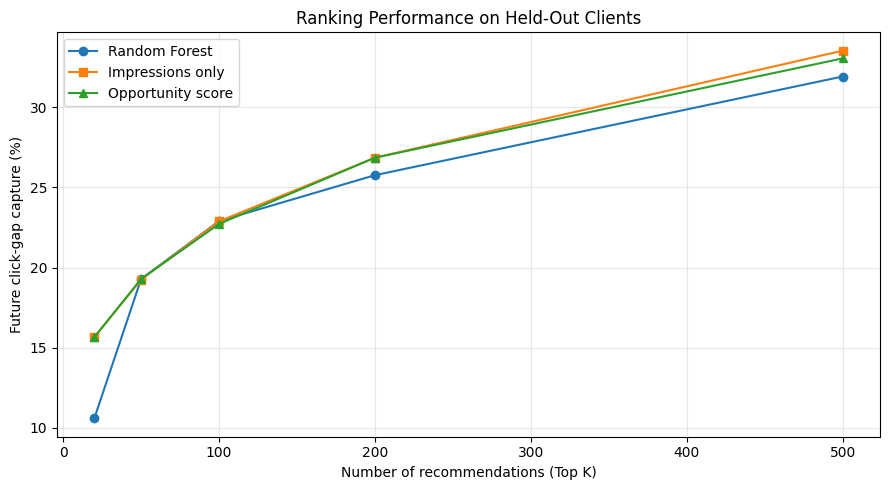

Saved: ranking_comparison.png


In [38]:

# Step 39: Create ranking comparison chart

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    ranking_comparison["Top K"],
    ranking_comparison["Random Forest"],
    marker="o",
    label="Random Forest"
)

plt.plot(
    ranking_comparison["Top K"],
    ranking_comparison["Impressions only"],
    marker="s",
    label="Impressions only"
)

plt.plot(
    ranking_comparison["Top K"],
    ranking_comparison["Opportunity score"],
    marker="^",
    label="Opportunity score"
)

plt.xlabel("Number of recommendations (Top K)")
plt.ylabel("Future click-gap capture (%)")
plt.title("Ranking Performance on Held-Out Clients")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ranking_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: ranking_comparison.png")


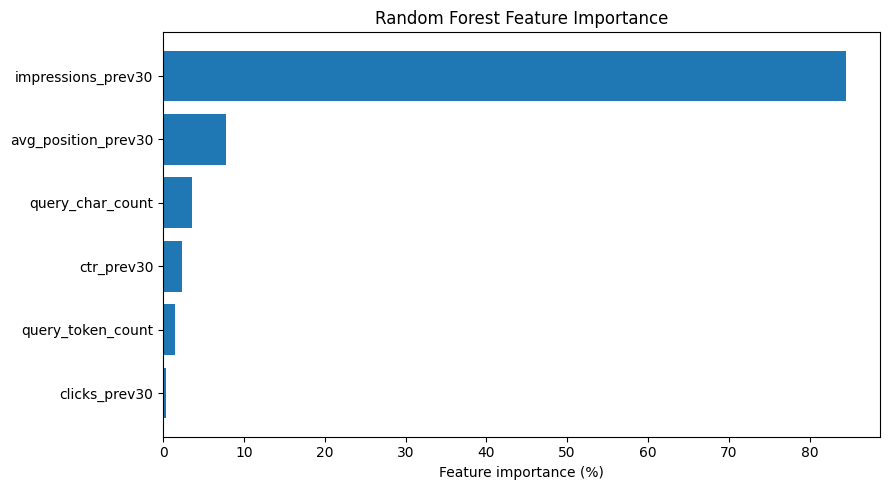

Saved: feature_importance.png


In [39]:

# Step 40: Create feature importance chart

import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gap_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"] * 100
)

plt.xlabel("Feature importance (%)")
plt.title("Random Forest Feature Importance")
plt.tight_layout()

plt.savefig(
    "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: feature_importance.png")


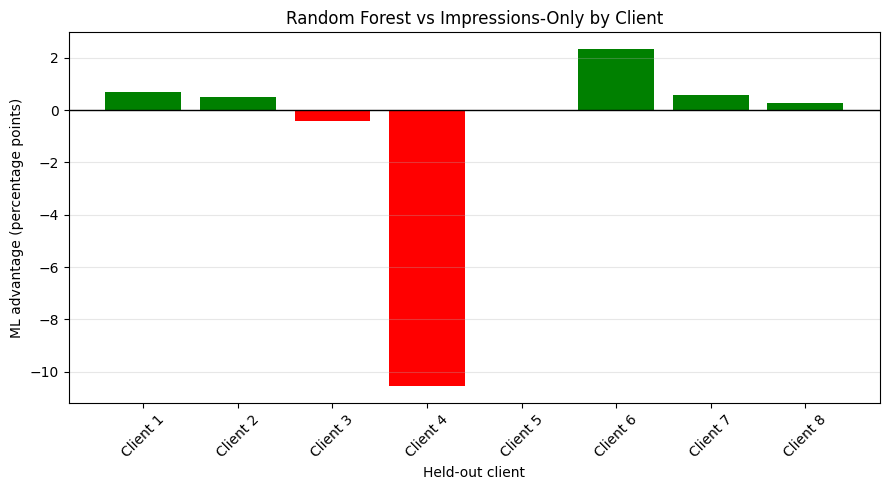

Saved: client_level_performance.png


In [40]:

# Step 41: Visualize client-level ML performance

import matplotlib.pyplot as plt

chart_data = client_results_export.copy()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    chart_data["client"],
    chart_data["ml_advantage_pp"],
    color=[
        "green" if value > 0 else "red"
        for value in chart_data["ml_advantage_pp"]
    ]
)

plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Held-out client")
plt.ylabel("ML advantage (percentage points)")
plt.title("Random Forest vs Impressions-Only by Client")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "client_level_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: client_level_performance.png")


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
